# 07 · Validation against the official perimeter (EFFIS)

**Question:** does our Sentinel-2 footprint match the official mapping of the fire?

**EFFIS** (European Forest Fire Information System) is the EU service that maps fires larger than about 30 ha from satellite images. It publishes each fire as a polygon with its date, municipality, area and the land cover it burned. We download those polygons through a **WFS** (Web Feature Service): a web address that returns map features, here as GeoJSON, for a box we ask for.

**Why it matters:** an independent map is the strongest check on our method. If two different teams, with different images and methods, trace almost the same shape, we can trust it.

In [1]:
import io
import geopandas as gpd
import pandas as pd
import requests
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from common import *

EFFIS_WFS = "https://maps.effis.emergency.copernicus.eu/effis"
w, s, e, n = CFG["bbox"]
r = requests.get(EFFIS_WFS, timeout=300, params={
    "service": "WFS", "version": "1.1.0", "request": "GetFeature",
    "typename": "ms:modis.ba.poly",           # EFFIS burnt areas, all years since 2016
    "bbox": f"{s},{w},{n},{e},EPSG:4326",     # WFS 1.1 with EPSG:4326 wants lat before lon
    "outputformat": "geojson"})
r.raise_for_status()
effis = gpd.read_file(io.BytesIO(r.content)).set_crs(4326, allow_override=True).to_crs(CFG["crs"])
effis["FIREDATE"] = pd.to_datetime(effis["FIREDATE"])
effis.to_file(OUT / "effis_burnt_areas_aoi.gpkg", driver="GPKG")
print(f"{len(effis)} EFFIS fires touch the AOI, years {effis.FIREDATE.dt.year.min()}-{effis.FIREDATE.dt.year.max()}")

47 EFFIS fires touch the AOI, years 2016-2026


## 1. Which EFFIS fires should we compare with?
Our footprint is a **change detection** between two images, so it contains everything that burned between them. The fair comparison is every EFFIS fire that started between the pre-fire and post-fire image dates and overlaps our footprint.

In [2]:
scenes = load_json("step1_scenes.json", "01")
pre, post = pd.Timestamp(scenes["pre"]["date"]), pd.Timestamp(scenes["post"]["date"])
fp = gpd.read_file(need("burn_footprint.gpkg", "04"), layer="footprint_dissolved").to_crs(CFG["crs"]).union_all()

effis["km2"] = effis.area / 1e6
effis["overlap_km2"] = effis.intersection(fp).area / 1e6
sel = effis[(effis.FIREDATE >= pre) & (effis.FIREDATE <= post) & (effis.overlap_km2 > 0)].sort_values("FIREDATE")
print(f"Images: {pre.date()} -> {post.date()}.  EFFIS fires in that window overlapping the footprint: {len(sel)}")
sel[["FIREDATE", "FINALDATE", "PROVINCE", "COMMUNE", "AREA_HA", "km2", "overlap_km2"]].round({"km2": 2, "overlap_km2": 2})

Images: 2026-06-24 -> 2026-08-08.  EFFIS fires in that window overlapping the footprint: 7


,FIREDATE,FINALDATE,PROVINCE,COMMUNE,AREA_HA,km2,overlap_km2
42,2026-07-04 14:14:00,2026-07-04 14:14:00,Ávila,Casavieja,24,0.24,0.23
35,2026-07-10 12:19:00,2026-07-10 13:14:00,Ávila,"Barraco, El",76,0.75,0.69
44,2026-07-22 13:36:00,2026-07-27 03:49:00,Ávila,Navaluenga,42458,424.43,406.67
43,2026-07-23 13:53:00,2026-07-26 03:49:00,Madrid,Navas del Rey,19939,199.29,181.20
38,2026-07-24 01:34:00,2026-07-24 02:11:00,Ávila,"Tiemblo, El",19,0.19,0.18
39,2026-07-24 12:19:00,2026-07-25 14:20:00,Ávila,"Barraco, El",1577,15.77,15.49
40,2026-07-31 13:23:00,2026-07-31 14:08:00,Madrid,San Martín de Valdeiglesias,35,0.35,0.34


## 2. How well do the two maps agree?
Imagine two people tracing the same shape on separate sheets of tracing paper. Laying one on top of the other, we measure:

- **% of our footprint inside EFFIS:** how much of what we called burned, EFFIS also called burned (few false alarms).
- **% of EFFIS captured by us:** how much of the official area we found (few misses).
- **Dice score:** both combined in one number, from 0 (no overlap) to 1 (identical shapes).

In [3]:
ef = sel.union_all()
both = fp.intersection(ef)
ours_only = fp.difference(ef)
effis_only = ef.difference(fp)
a = lambda g: g.area / 1e6
val = {
    "effis_fires": int(len(sel)),
    "effis_km2": round(a(ef), 2),
    "footprint_km2": round(a(fp), 2),
    "both_km2": round(a(both), 2),
    "ours_only_km2": round(a(ours_only), 2),
    "effis_only_km2": round(a(effis_only), 2),
    "pct_footprint_inside_effis": round(100 * a(both) / a(fp), 1),
    "pct_effis_captured": round(100 * a(both) / a(ef), 1),
    "dice": round(2 * a(both) / (a(fp) + a(ef)), 3),
}
for k, v in val.items():
    print(f"{k:28s} {v}")

effis_fires                  7
effis_km2                    641.02
footprint_km2                618.03
both_km2                     604.79
ours_only_km2                13.24
effis_only_km2               36.23
pct_footprint_inside_effis   97.9
pct_effis_captured           94.3
dice                         0.961


## 3. Where do they disagree?
Most disagreement between two good maps sits along the edges, where one map's line is a few pixels away from the other's. This measures how much of it is within 100 m of the EFFIS boundary. The rest is real disagreement (for example unburned islands that one map kept and the other filled in).

Disagreement within 100 m of the EFFIS edge: 43.8%


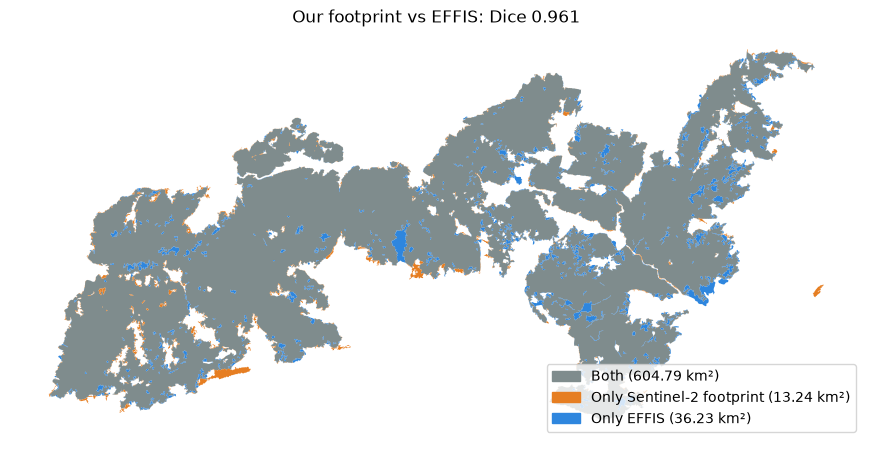

In [4]:
edge = ef.boundary.buffer(100)
disagree = ours_only.union(effis_only)
val["pct_disagreement_within_100m_of_edge"] = round(100 * a(disagree.intersection(edge)) / a(disagree), 1)
print(f"Disagreement within 100 m of the EFFIS edge: {val['pct_disagreement_within_100m_of_edge']}%")

fig, ax = plt.subplots(figsize=(11, 7))
gpd.GeoSeries([both], crs=CFG["crs"]).plot(ax=ax, color="#7f8c8d")
gpd.GeoSeries([ours_only], crs=CFG["crs"]).plot(ax=ax, color="#e67e22")
gpd.GeoSeries([effis_only], crs=CFG["crs"]).plot(ax=ax, color="#2e86de")
ax.legend(handles=[Patch(color="#7f8c8d", label=f"Both ({val['both_km2']} km²)"),
                   Patch(color="#e67e22", label=f"Only Sentinel-2 footprint ({val['ours_only_km2']} km²)"),
                   Patch(color="#2e86de", label=f"Only EFFIS ({val['effis_only_km2']} km²)")], loc="lower right")
ax.set_title(f"Our footprint vs EFFIS: Dice {val['dice']}")
ax.set_axis_off()
fig.savefig(OUT / "step7_validation_map.png", dpi=150, bbox_inches="tight")
gpd.GeoDataFrame({"part": ["both", "ours_only", "effis_only"]},
                 geometry=[both, ours_only, effis_only], crs=CFG["crs"]).to_file(OUT / "effis_comparison.gpkg", driver="GPKG")
sel.to_file(OUT / "effis_perimeters.gpkg", driver="GPKG")

## 4. What did it burn? (EFFIS land cover)
EFFIS reports, for each fire, the percentage of each land-cover type it burned, from **CORINE Land Cover** (the EU land-use map). Unlike the ESA WorldCover map in notebook 05, it separates broadleaf, conifer and mixed forest. Weighting each fire by its area gives the split for the whole complex. `PERCNA2K` is the share inside Natura 2000 protected sites, which we can compare with notebook 05.

In [5]:
LC = {"BROADLEA": "Broadleaf forest", "CONIFER": "Conifer forest", "MIXED": "Mixed forest",
      "SCLEROPH": "Sclerophyllous scrub", "TRANSIT": "Transitional woodland-shrub",
      "OTHERNATLC": "Other natural land", "AGRIAREAS": "Agricultural areas",
      "ARTIFSURF": "Artificial surfaces", "OTHERLC": "Other"}
wts = sel["AREA_HA"].astype(float)
pct = {name: float((sel[col].astype(float) * wts).sum() / wts.sum()) for col, name in LC.items()}
cover = pd.Series(pct, name="pct_of_burned_area").sort_values(ascending=False).round(1)
val["effis_landcover_pct"] = cover.to_dict()
val["effis_pct_in_natura2000"] = round(float((sel["PERCNA2K"].astype(float) * wts).sum() / wts.sum()), 1)
impact = load_json("step5_impact.json", "05")
ours_n2k = 100 * impact["overlays"]["Natura 2000"]["burned_km2"] / val["footprint_km2"]
print(f"Inside Natura 2000: EFFIS {val['effis_pct_in_natura2000']}%, our footprint {ours_n2k:.1f}%")
save_json(val, "step7_validation.json")
cover.to_frame()

Inside Natura 2000: EFFIS 81.7%, our footprint 81.3%


,pct_of_burned_area
Mixed forest,25.7
Sclerophyllous scrub,20.7
Conifer forest,18.6
Broadleaf forest,10.3
Agricultural areas,10.0
Other natural land,7.8
Transitional woodland-shrub,5.8
Artificial surfaces,1.0
Other,0.1


## What you learned
- **Validation** means comparing with an independent source, not with yourself.
- Two numbers describe agreement: how much of your map is right (false alarms) and how much of the truth you found (misses). The **Dice score** combines them.
- **Map edges** cause most of the disagreement between two good maps; check that before blaming the method.
- A **WFS** is like the Open-Meteo API in notebook 06, but it returns map shapes instead of tables.

Next: notebook 08 shows how the fire spread day by day.